# DSP Activity 2: Operations on Sequences
Shifting (delay/advance), folding (time reversal), amplitude scaling, addition, multiplication, and time scaling of discrete-time sequences.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_seq(n, x, title, ax=None):
    ax = ax or plt.gca()
    ax.stem(n, x)
    ax.set_title(title)
    ax.set_xlabel('n')
    ax.set_ylabel('x(n)')
    ax.grid(True)

# Helper: align two sequences on a common n-axis (zero padded)
def align(n1, x1, n2, x2):
    n = np.arange(min(n1.min(), n2.min()), max(n1.max(), n2.max()) + 1)
    y1 = np.zeros(len(n)); y2 = np.zeros(len(n))
    y1[(n >= n1.min()) & (n <= n1.max())] = x1
    y2[(n >= n2.min()) & (n <= n2.max())] = x2
    return n, y1, y2

## Original sequence

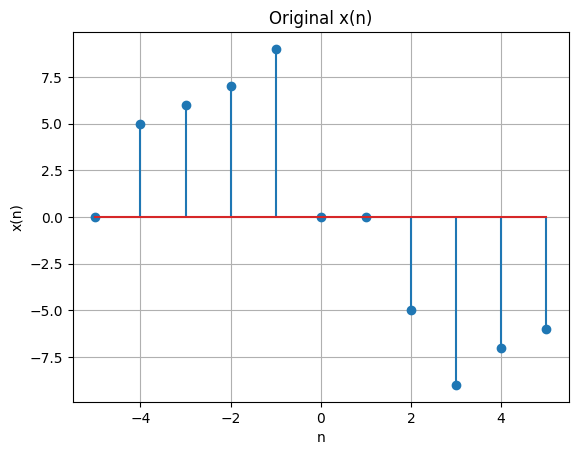

In [ ]:
n = np.arange(-5, 6)
x = np.array([0, 5, 6, 7, 9, 0, 0, -5, -9, -7, -6])
plot_seq(n, x, 'Original x(n)')
plt.show()

## 1. Shifting:  y(n) = x(n − k)
k > 0 delays the sequence (shifts right); k < 0 advances it (shifts left).

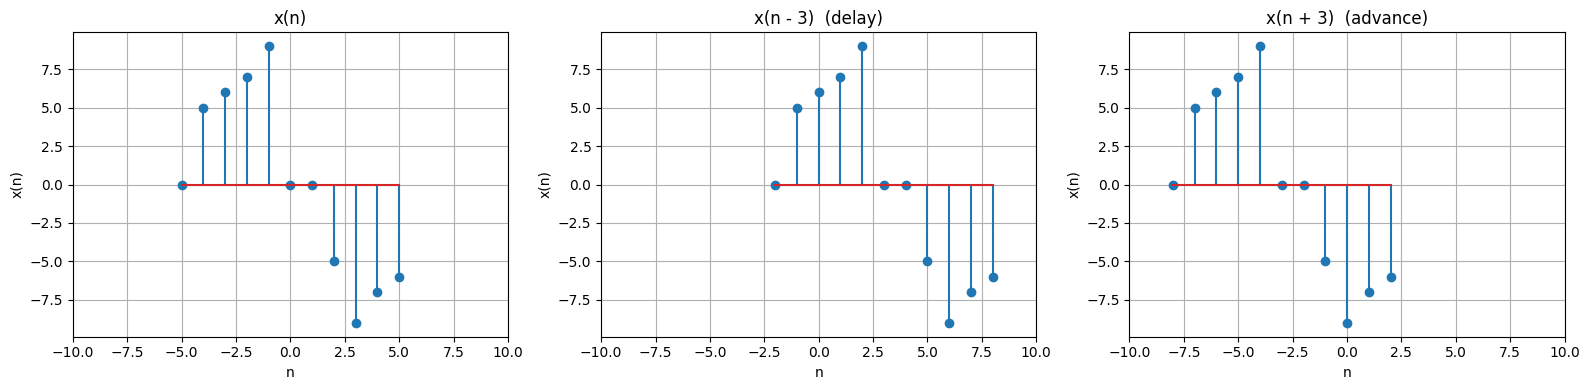

In [ ]:
k = 3
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
plot_seq(n, x, 'x(n)', axs[0])
plot_seq(n + k, x, f'x(n - {k})  (delay)', axs[1])
plot_seq(n - k, x, f'x(n + {k})  (advance)', axs[2])
for a in axs: a.set_xlim(-10, 10)
plt.tight_layout(); plt.show()

## 2. Folding:  y(n) = x(−n)

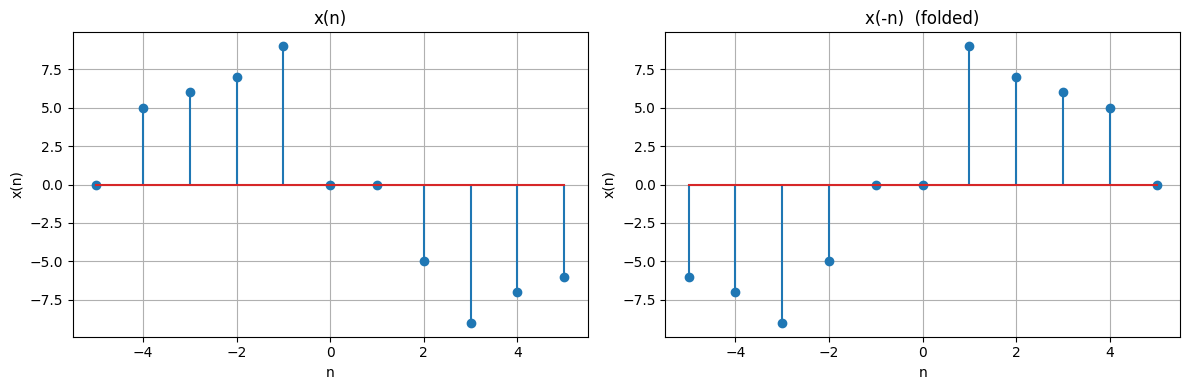

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
plot_seq(n, x, 'x(n)', axs[0])
plot_seq(-n[::-1], x[::-1], 'x(-n)  (folded)', axs[1])
plt.tight_layout(); plt.show()

## 3. Amplitude scaling:  y(n) = A·x(n)

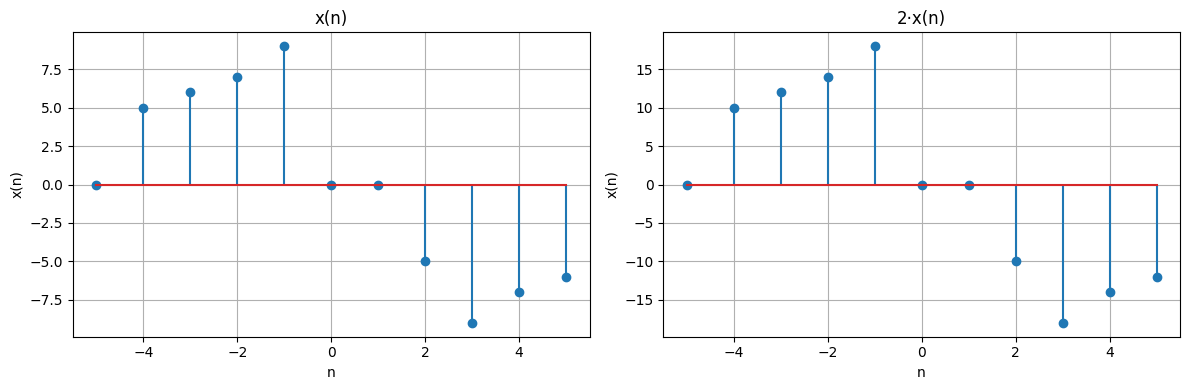

In [ ]:
A = 2
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
plot_seq(n, x, 'x(n)', axs[0])
plot_seq(n, A * x, f'{A}·x(n)', axs[1])
plt.tight_layout(); plt.show()

## 4. Addition and multiplication of two sequences

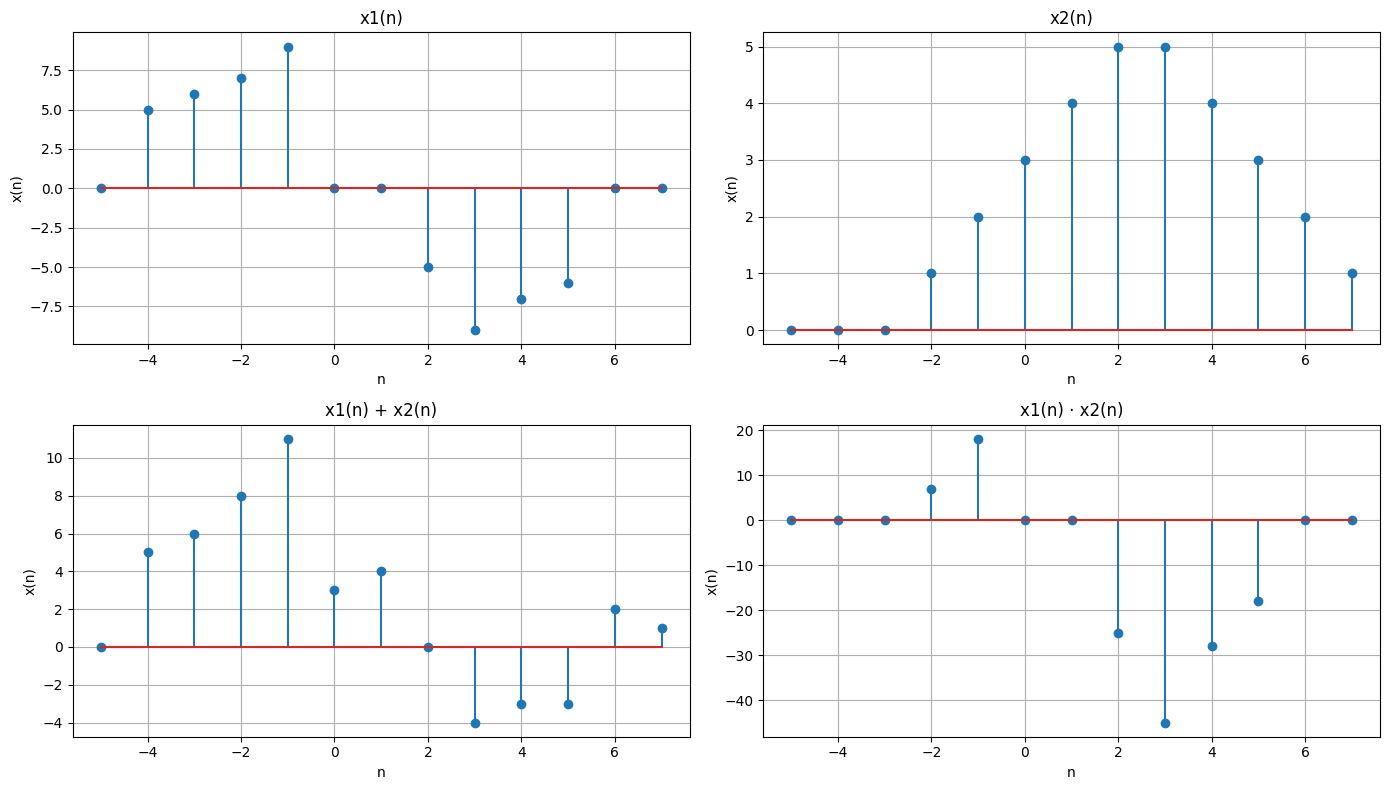

In [ ]:
n1 = np.arange(-5, 6); x1 = np.array([0, 5, 6, 7, 9, 0, 0, -5, -9, -7, -6])
n2 = np.arange(-2, 8); x2 = np.array([1, 2, 3, 4, 5, 5, 4, 3, 2, 1])

n_c, a, b = align(n1, x1, n2, x2)

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
plot_seq(n_c, a, 'x1(n)', axs[0, 0])
plot_seq(n_c, b, 'x2(n)', axs[0, 1])
plot_seq(n_c, a + b, 'x1(n) + x2(n)', axs[1, 0])
plot_seq(n_c, a * b, 'x1(n) · x2(n)', axs[1, 1])
plt.tight_layout(); plt.show()

## 5. Time scaling (down-sampling / up-sampling)

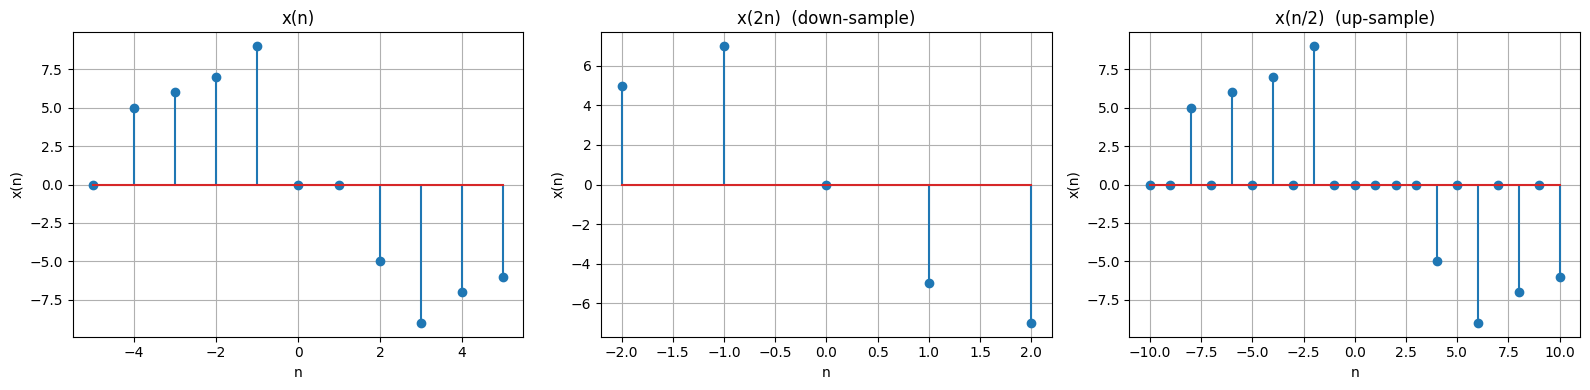

In [ ]:
# Down-sampling by 2: y(n) = x(2n)
even = (n % 2 == 0)
n_d = n[even] // 2
x_d = x[even]

# Up-sampling by 2: insert zeros between samples
x_u = np.zeros(2 * len(x) - 1)
x_u[::2] = x
n_u = np.arange(len(x_u)) + 2 * n[0]

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
plot_seq(n, x, 'x(n)', axs[0])
plot_seq(n_d, x_d, 'x(2n)  (down-sample)', axs[1])
plot_seq(n_u, x_u, 'x(n/2)  (up-sample)', axs[2])
plt.tight_layout(); plt.show()

## 6. Even and odd decomposition

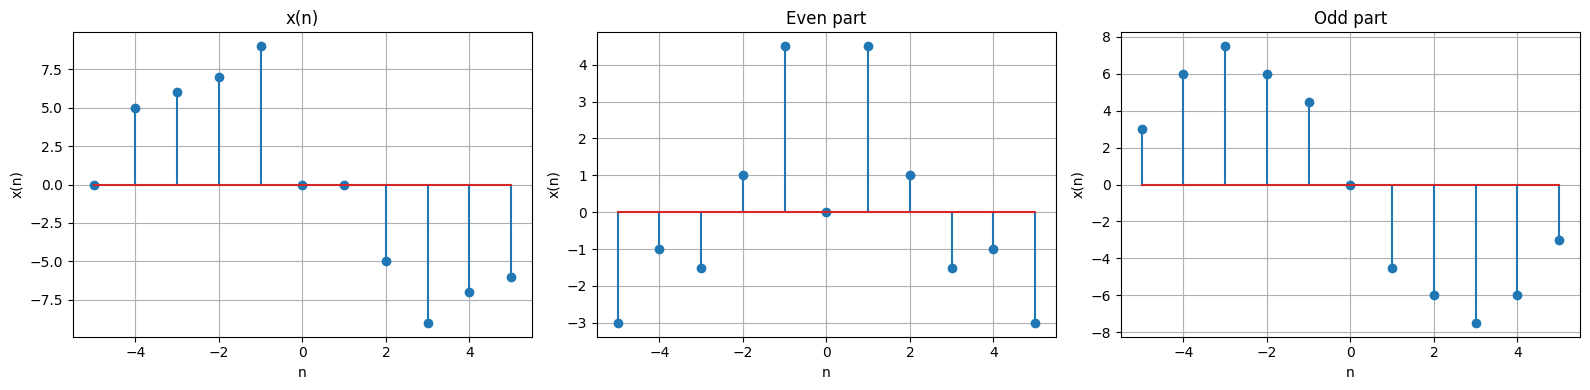

Even + Odd == x ? True


In [8]:
xf = x[::-1]
xe = 0.5 * (x + xf)
xo = 0.5 * (x - xf)
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
plot_seq(n, x, 'x(n)', axs[0])
plot_seq(n, xe, 'Even part', axs[1])
plot_seq(n, xo, 'Odd part', axs[2])
plt.tight_layout(); plt.show()
print('Even + Odd == x ?', np.allclose(xe + xo, x))